# 🎨 Diffusion Model Fine-Tuning: text2img, img2img and img2text

This notebook fine-tunes Stable Diffusion 1.5 on a small set of flower or bird photos using **LoRA**, then uses the result three ways:

| Mode | Input → output | Model doing the work |
|---|---|---|
| **text2img** | prompt → new image | Stable Diffusion 1.5 + your LoRA |
| **img2img** | image + prompt → changed image | Stable Diffusion 1.5 + your LoRA |
| **img2text** | image → caption | BLIP, a separate caption model |

**LoRA** trains a small set of extra weights (a few MB) on top of the unchanged 4 GB base model, which is why it fits in minutes on a free GPU.

**To run:** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*. Allow Google Drive access when asked, so the trained weights survive a disconnect.

**Time on a T4:** about 8 minutes end to end, of which about 3 minutes is training.

The saved outputs of the cells that display dataset photos are cleared. Running the notebook shows them.

In [1]:
#@title ⚙️ Settings
DATASET = "flowers"     #@param ["flowers", "birds"]
NUM_IMAGES = 200        #@param {type:"integer"}
MAX_TRAIN_STEPS = 400   #@param {type:"integer"}
# More steps = a stronger effect and a longer run (about 2.5 steps per second on a T4).

LORA_RANK = 8           #@param {type:"integer"}
LEARNING_RATE = 1e-4    #@param {type:"number"}
INFERENCE_STEPS = 25    #@param {type:"integer"}
GUIDANCE_SCALE = 7.5    #@param {type:"number"}
SEED = 1337             #@param {type:"integer"}
SAVE_TO_DRIVE = True    #@param {type:"boolean"}

RESOLUTION = 512
HELD_OUT_IMAGES = 6     # kept out of training, used by img2img and img2text
BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"
CAPTION_MODEL = "Salesforce/blip-image-captioning-base"
DIFFUSERS_VERSION = "0.42.1"   # the library and the training script must match

WORK_DIR = "/content/diffusion_finetuning"
DRIVE_DIR = "/content/drive/MyDrive/diffusion_finetuning"

# Both datasets have an "image" column and a "text" caption column.
DATASETS = {
    "flowers": {
        "id": "pranked03/flowers-blip-captions",   # Oxford 102 Flowers
        "prompts": ["a close up of a purple passion flower",
                    "a red rose with green leaves",
                    "a yellow sunflower in a field"],
        "img2img_prompt": "a watercolor painting of a flower",
    },
    "birds": {
        "id": "anjunhu/naively_captioned_CUB2002011_train",   # Caltech-UCSD Birds 200
        "prompts": ["A photo of a painted bunting",
                    "A photo of a blue jay",
                    "A photo of a ruby throated hummingbird"],
        "img2img_prompt": "a watercolor painting of a bird",
    },
}
CHOSEN = DATASETS[DATASET]
print("Dataset:", CHOSEN["id"], "|", NUM_IMAGES, "images,", MAX_TRAIN_STEPS, "steps")

Dataset: pranked03/flowers-blip-captions | 200 images, 400 steps


In [2]:
#@title 📦 Install the libraries and download the training script
%pip install -q "diffusers=={DIFFUSERS_VERSION}" transformers accelerate datasets peft safetensors
# Colab's torchao is too old for PEFT, which then refuses to add the LoRA. This notebook does not use it.
%pip uninstall -q -y torchao

import urllib.request
from pathlib import Path

TRAIN_SCRIPT = Path(WORK_DIR) / "train_text_to_image_lora.py"
TRAIN_SCRIPT.parent.mkdir(parents=True, exist_ok=True)
urllib.request.urlretrieve(
    f"https://raw.githubusercontent.com/huggingface/diffusers/v{DIFFUSERS_VERSION}"
    "/examples/text_to_image/train_text_to_image_lora.py",
    TRAIN_SCRIPT,
)
print("Training script ready:", TRAIN_SCRIPT)

Training script ready: /content/diffusion_finetuning/train_text_to_image_lora.py


In [3]:
#@title 🔧 Setup: GPU, Google Drive and folders
import gc
import json
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from PIL import Image

if torch.cuda.is_available():
    DEVICE, DTYPE, MIXED_PRECISION = "cuda", torch.float16, "fp16"
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE, DTYPE, MIXED_PRECISION = "cpu", torch.float32, "no"
    print("No GPU found: this will be very slow. Choose Runtime > Change runtime type > T4 GPU.")

WORK = Path(WORK_DIR)
TRAIN_DIR = WORK / "train"          # images + metadata.jsonl
HELD_OUT_DIR = WORK / "held_out"    # images never used in training
LORA_DIR = WORK / "lora"            # the trained weights
OUTPUT_DIR = WORK / "outputs"       # generated images
for folder in (TRAIN_DIR, HELD_OUT_DIR, LORA_DIR, OUTPUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SAVE_DIR = None
if SAVE_TO_DRIVE:
    from google.colab import drive
    try:
        drive.mount("/content/drive")
    except Exception as error:
        # Drive is only a backup, so a refused mount should not stop the run.
        print(f"Google Drive not mounted ({error}). Continuing: weights and images stay in {WORK_DIR} until this runtime ends.")
    else:
        SAVE_DIR = Path(DRIVE_DIR)
        SAVE_DIR.mkdir(parents=True, exist_ok=True)
        print("Weights and images will also be copied to:", SAVE_DIR)


def show_images(images, titles, columns=3, size=4):
    # Draw images in a grid, with a title above each one.
    rows = (len(images) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(columns * size, rows * (size + 0.5)), squeeze=False)
    for ax in axes.flatten():
        ax.axis("off")
    for ax, image, title in zip(axes.flatten(), images, titles):
        ax.imshow(image)
        ax.set_title(title, fontsize=10, wrap=True)
    plt.tight_layout()
    plt.show()

GPU: Tesla T4
Mounted at /content/drive
Weights and images will also be copied to: /content/drive/MyDrive/diffusion_finetuning


## 1. Data

The notebook downloads the chosen dataset, shuffles it (the rows are sorted by species), and keeps `NUM_IMAGES` photos with their captions for training. A few more are held out: the model never trains on them, so img2img and img2text work on images it has not seen.

In [4]:
#@title 📚 Prepare the training images and captions
from datasets import load_dataset

dataset = load_dataset(CHOSEN["id"], split="train").shuffle(seed=SEED)
print("Available images:", len(dataset))

held_out = []
with (TRAIN_DIR / "metadata.jsonl").open("w", encoding="utf-8") as metadata:
    for i, row in enumerate(dataset.select(range(NUM_IMAGES + HELD_OUT_IMAGES))):
        image, caption = row["image"].convert("RGB"), str(row["text"]).strip()
        if i < NUM_IMAGES:
            image.save(TRAIN_DIR / f"{i:04d}.png")
            metadata.write(json.dumps({"file_name": f"{i:04d}.png", "text": caption}) + "\n")
        else:
            image.save(HELD_OUT_DIR / f"{i:04d}.png")
            held_out.append((image, caption))

records = [json.loads(line) for line in (TRAIN_DIR / "metadata.jsonl").read_text(encoding="utf-8").splitlines()]
print(f"Saved {len(records)} training images and {len(held_out)} held-out images.")

preview = records[:6]
show_images([Image.open(TRAIN_DIR / r["file_name"]) for r in preview], [r["text"] for r in preview])

Available images: 6552
Saved 200 training images and 6 held-out images.


## 2. Fine-tuning

Each training step takes one image and its caption, adds random noise to it, and asks the model to predict that noise. Only the small LoRA weights are updated; the base model stays frozen.

Compared with a default setup, three choices keep this run short: no validation images during training, no intermediate checkpoints, and images read from the local disk instead of Google Drive.

In [5]:
#@title 🚀 Train the LoRA
train_args = " ".join([
    f"--pretrained_model_name_or_path={BASE_MODEL}",
    f"--train_data_dir={TRAIN_DIR.as_posix()}",
    "--image_column=image",
    "--caption_column=text",
    f"--resolution={RESOLUTION}",
    "--center_crop",
    "--random_flip",
    "--train_batch_size=1",
    f"--max_train_steps={MAX_TRAIN_STEPS}",
    f"--learning_rate={LEARNING_RATE}",
    "--lr_scheduler=cosine",
    "--lr_warmup_steps=0",
    "--max_grad_norm=1.0",
    f"--rank={LORA_RANK}",
    f"--checkpointing_steps={MAX_TRAIN_STEPS + 1}",
    f"--seed={SEED}",
    "--dataloader_num_workers=0",
    f"--mixed_precision={MIXED_PRECISION}",
    f"--output_dir={LORA_DIR.as_posix()}",
])
!accelerate launch --mixed_precision={MIXED_PRECISION} {TRAIN_SCRIPT.as_posix()} {train_args}

The following values were not passed to `accelerate launch` and had defaults used instead:
	`--num_processes` was set to a value of `1`
	`--num_machines` was set to a value of `1`
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
11/07/2026 06:08:26 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cuda
Mixed precision type: fp16
scheduler_config.json: 100% 308/308 [00:00<00:00, 1.83MB/s]
{'sample_max_value', 'thresholding', 'rescale_betas_zero_snr', 'timestep_spacing', 'variance_type', 'clip_sample_range', 'prediction_type', 'dynamic_thresholding_ratio'} was not found in config. Values will be initialized to default values.
tokenizer_config.json: 100% 806/806 [00:00<00:00, 3.81MB/s]
vocab.json: 100% 1.06M/1.06M [00:00<00:00, 43.9MB/s]
merges.txt: 100% 525k/525k [00:00<00:00, 107MB/s]
special_token

In [6]:
#@title 💾 Check and save the trained weights
LORA_FILE = LORA_DIR / "pytorch_lora_weights.safetensors"
assert LORA_FILE.exists(), f"LoRA weights not found at {LORA_FILE}: check the training output above."
print(f"LoRA weights: {LORA_FILE.stat().st_size / 1024 / 1024:.1f} MB")

if SAVE_DIR:
    shutil.copy2(LORA_FILE, SAVE_DIR / LORA_FILE.name)
    print("Copied to:", SAVE_DIR / LORA_FILE.name)

LoRA weights: 6.1 MB
Copied to: /content/drive/MyDrive/diffusion_finetuning/pytorch_lora_weights.safetensors


## 3. text2img: prompt → image

The base model and the fine-tuned model each draw the same prompts from the same random seed, so any difference comes from the LoRA. Stable Diffusion already knows flowers and birds well, so expect a shift towards the look of the training photos, not a completely different picture.

In [7]:
#@title 🖌️ Load Stable Diffusion with the LoRA
from diffusers import StableDiffusionImg2ImgPipeline, StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained(
    BASE_MODEL, safety_checker=None, requires_safety_checker=False, dtype=DTYPE,
).to(DEVICE)
pipe.load_lora_weights(str(LORA_DIR), weight_name=LORA_FILE.name, adapter_name="finetuned")
pipe.set_progress_bar_config(disable=True)

# The image-to-image pipeline shares the same model in memory, including the LoRA.
# dtype must be repeated: from_pipe would otherwise convert the shared model to float32.
img2img_pipe = StableDiffusionImg2ImgPipeline.from_pipe(pipe, dtype=DTYPE)
img2img_pipe.set_progress_bar_config(disable=True)


def new_generator():
    return torch.Generator(device=DEVICE).manual_seed(SEED)


def text2img(prompt, use_lora=True):
    pipe.enable_lora() if use_lora else pipe.disable_lora()
    return pipe(prompt, height=RESOLUTION, width=RESOLUTION, num_inference_steps=INFERENCE_STEPS,
                guidance_scale=GUIDANCE_SCALE, generator=new_generator()).images[0]


def img2img(image, prompt, strength=0.6, use_lora=True):
    # strength: 0 keeps the input image, 1 ignores it.
    pipe.enable_lora() if use_lora else pipe.disable_lora()
    image = image.convert("RGB").resize((RESOLUTION, RESOLUTION))
    return img2img_pipe(prompt, image=image, strength=strength, num_inference_steps=INFERENCE_STEPS,
                        guidance_scale=GUIDANCE_SCALE, generator=new_generator()).images[0]


print("Ready.")

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Ready.


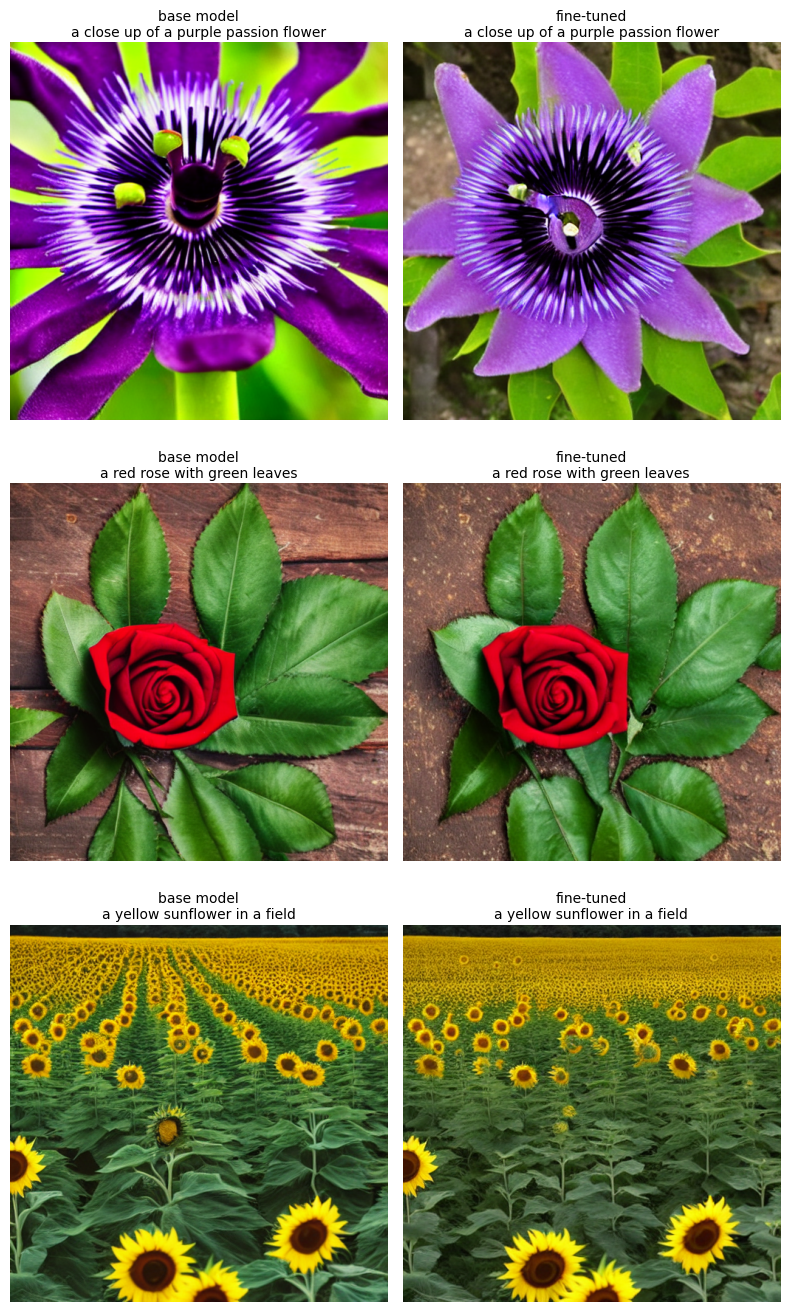

In [8]:
#@title ✍️ text2img: base model vs fine-tuned model
images, titles = [], []
for prompt in CHOSEN["prompts"]:
    for use_lora, label in ((False, "base model"), (True, "fine-tuned")):
        image = text2img(prompt, use_lora)
        images.append(image)
        titles.append(f"{label}\n{prompt}")

for index, image in enumerate(images):
    image.save(OUTPUT_DIR / f"text2img_{index}.png")
show_images(images, titles, columns=2)

## 4. img2img: image + prompt → changed image

Stable Diffusion adds noise to a starting image and then removes it, guided by your prompt. `strength` sets how much noise is added: low values stay close to the original, high values follow the prompt more freely. The starting image here is one the model never trained on.

In [9]:
#@title 🔁 img2img: the same image at three strengths
source_image, source_caption = held_out[0]
prompt = CHOSEN["img2img_prompt"]

images, titles = [source_image], [f"original\n{source_caption}"]
for strength in (0.3, 0.5, 0.75):
    image = img2img(source_image, prompt, strength)
    image.save(OUTPUT_DIR / f"img2img_{strength}.png")
    images.append(image)
    titles.append(f"strength {strength}\n{prompt}")

show_images(images, titles, columns=4)

## 5. img2text: image → caption

A diffusion model turns text into images, not the other way round, so this step uses **BLIP**, a separate model trained to describe images. It is not affected by the LoRA and is not fine-tuned here. BLIP also wrote the captions of the flowers dataset, so this is the reverse direction of the data the LoRA learned from.

In [10]:
#@title 💬 img2text: caption images with BLIP
from transformers import BlipForConditionalGeneration, BlipProcessor

processor = BlipProcessor.from_pretrained(CAPTION_MODEL)
captioner = BlipForConditionalGeneration.from_pretrained(CAPTION_MODEL, dtype=DTYPE).to(DEVICE)


def img2text(image, max_new_tokens=30):
    inputs = processor(images=image.convert("RGB"), return_tensors="pt").to(DEVICE, DTYPE)
    with torch.inference_mode():
        output = captioner.generate(**inputs, max_new_tokens=max_new_tokens)
    return processor.decode(output[0], skip_special_tokens=True)


images, titles = [], []
for image, dataset_caption in held_out[:3]:
    images.append(image)
    titles.append(f"BLIP: {img2text(image)}\ndataset: {dataset_caption}")
show_images(images, titles)

## 6. All three together

text2img draws a picture, img2text describes it, and img2img repaints it using that description.

text2img prompt: a close up of a purple passion flower
img2text caption: a purple flower with green leaves in the background


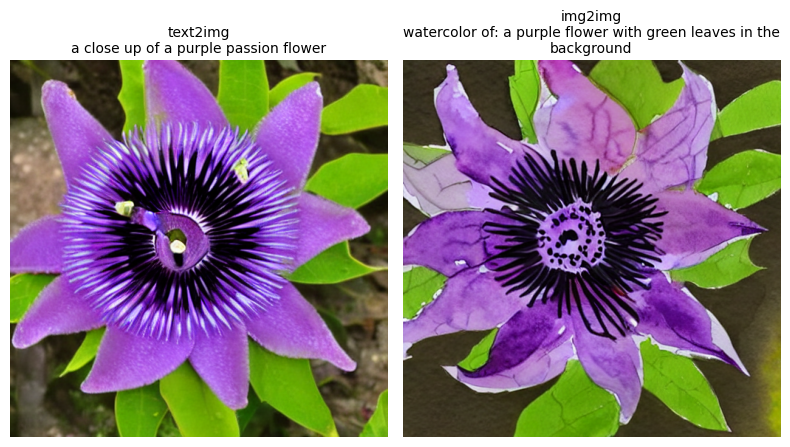

Images copied to: /content/drive/MyDrive/diffusion_finetuning/outputs


In [11]:
#@title 🔗 text2img → img2text → img2img
start_prompt = CHOSEN["prompts"][0]
drawn = text2img(start_prompt)
caption = img2text(drawn)
repainted = img2img(drawn, f"a watercolor painting of {caption}", strength=0.6)

for name, image in (("chain_text2img", drawn), ("chain_img2img", repainted)):
    image.save(OUTPUT_DIR / f"{name}.png")
print("text2img prompt:", start_prompt)
print("img2text caption:", caption)
show_images([drawn, repainted], [f"text2img\n{start_prompt}", f"img2img\nwatercolor of: {caption}"], columns=2)

if SAVE_DIR:
    shutil.copytree(OUTPUT_DIR, SAVE_DIR / "outputs", dirs_exist_ok=True)
    print("Images copied to:", SAVE_DIR / "outputs")

## Tips

- **Birds instead of flowers:** set `DATASET = "birds"` in Settings and run all again.
- **A stronger effect:** raise `MAX_TRAIN_STEPS` (for example to 1000, about 7 minutes of training) or `LORA_RANK` (for example to 16).
- **Your own image:** upload it in the Files panel, then run `img2text(Image.open("my_photo.jpg"))` or `img2img(Image.open("my_photo.jpg"), "your prompt")` in a new cell.